In [1]:
!pip uninstall -y torchao
!pip install -q -U diffusers transformers accelerate safetensors

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


Using device: cuda


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Time taken: 5.0 seconds


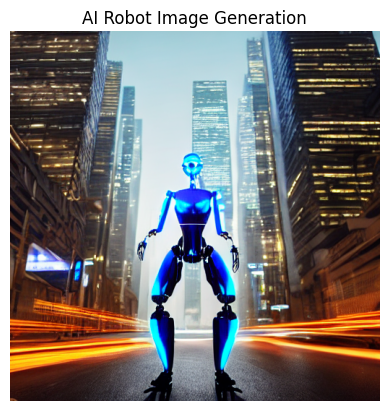

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

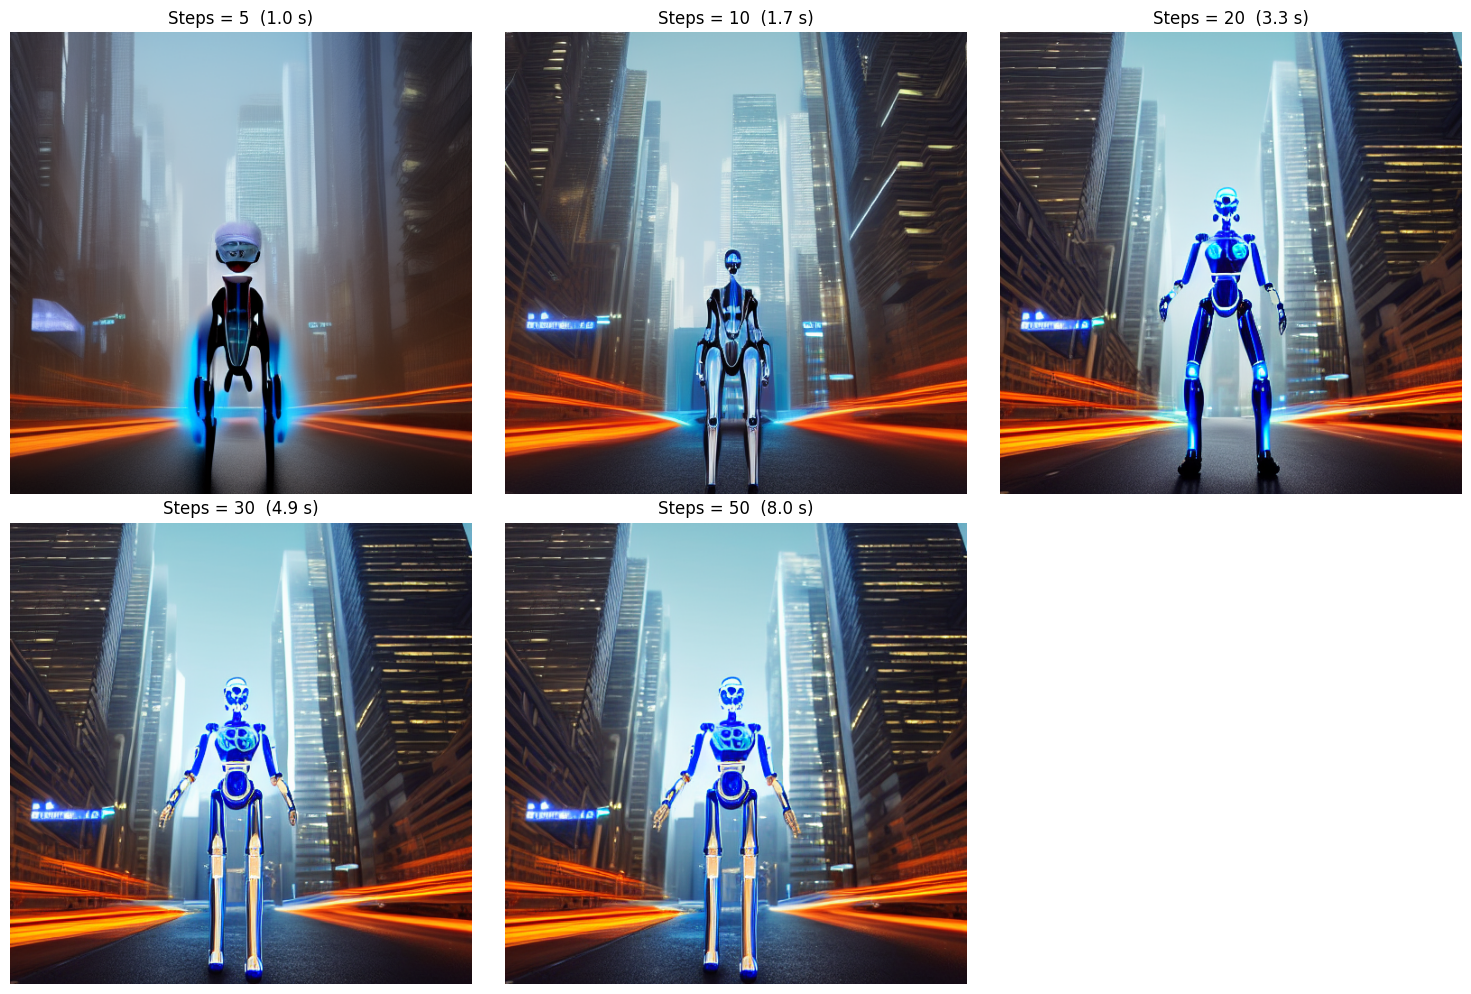

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

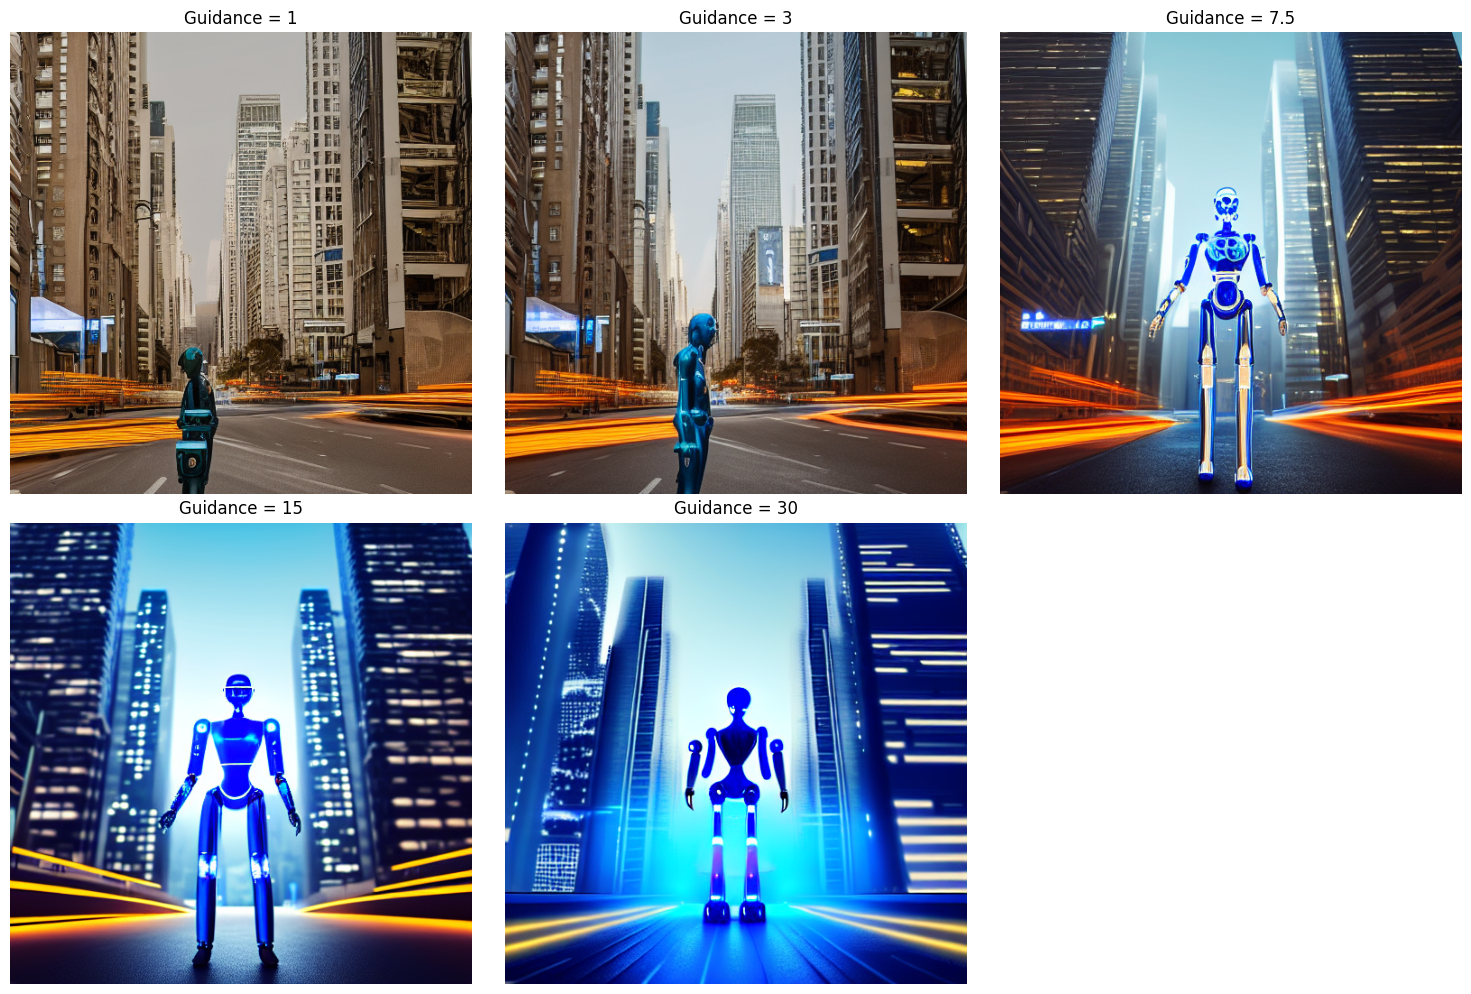

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

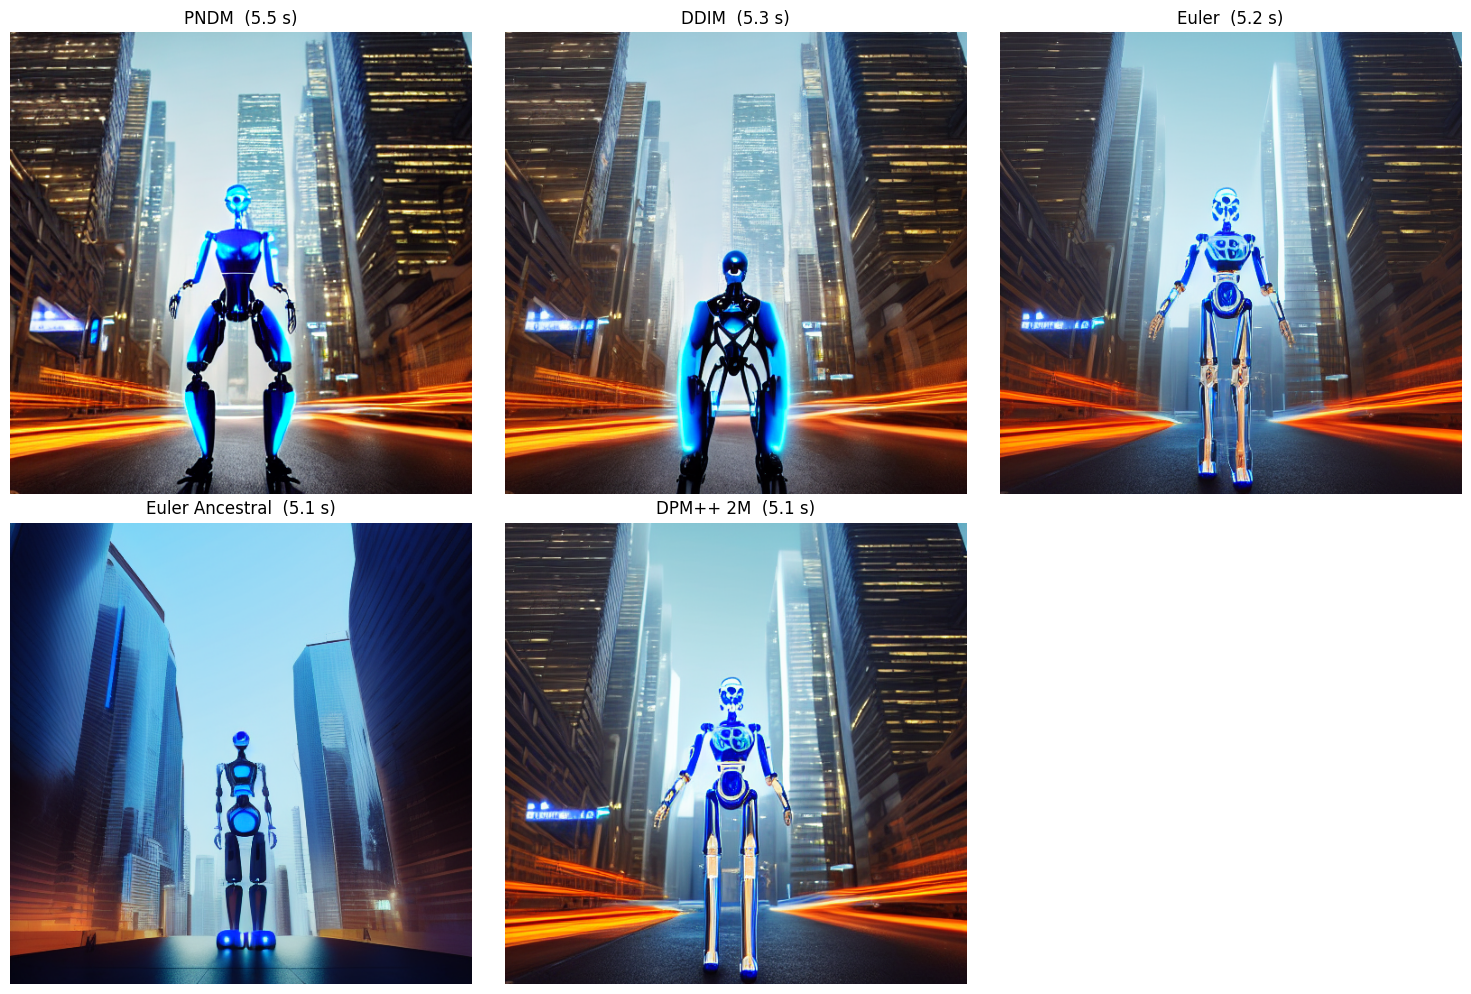

In [3]:
# =====================================================================
# Practical 05: Image Generation using Pretrained Stable Diffusion
# Aim: Generate images from text and study the effect of
#      1) inference steps  2) guidance scale  3) sampling methods
# Run in Google Colab with GPU: Runtime > Change runtime type > T4 GPU
# =====================================================================


# ---------------------------------------------------------------------
# CELL 1: Install libraries (run once, then restart runtime if asked)
# ---------------------------------------------------------------------
# !pip uninstall -y torchao
# !pip install -q -U diffusers transformers accelerate safetensors


# ---------------------------------------------------------------------
# CELL 2: Import libraries
# ---------------------------------------------------------------------
import time                                   # to measure time taken
import torch                                  # deep learning library (runs the model)
import matplotlib.pyplot as plt               # to show images and graphs
from diffusers import (
    StableDiffusionPipeline,                  # the complete text-to-image model
    PNDMScheduler,                            # sampling method 1
    DDIMScheduler,                            # sampling method 2
    EulerDiscreteScheduler,                   # sampling method 3
    EulerAncestralDiscreteScheduler,          # sampling method 4
    DPMSolverMultistepScheduler,              # sampling method 5
)


# ---------------------------------------------------------------------
# CELL 3: Load the pretrained Stable Diffusion model
# ---------------------------------------------------------------------
# Use GPU if available (much faster), otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Load the pretrained model from Hugging Face (first time = big download)
# float16 = half precision: uses less memory and runs faster on GPU
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
)
pipe = pipe.to(device)                        # move the model to the GPU
pipe.safety_checker = None                    # switch off NSFW filter (it can wrongly give black images)

# Save the default scheduler settings so we can build other schedulers from it
scheduler_config = pipe.scheduler.config


# ---------------------------------------------------------------------
# CELL 4: A helper function that generates ONE image
# ---------------------------------------------------------------------
def generate(prompt, steps=30, guidance=7.5, seed=42):
    # The seed fixes the starting random noise, so results can be compared fairly
    generator = torch.Generator(device=device).manual_seed(seed)

    start = time.time()                       # start the stopwatch
    image = pipe(
        prompt,                               # text description of the image
        num_inference_steps=steps,            # number of denoising steps
        guidance_scale=guidance,              # how strongly to follow the prompt
        generator=generator,                  # fixed seed
    ).images[0]                               # the pipeline returns a list; take the first image
    seconds = time.time() - start             # stop the stopwatch

    return image, seconds


# ---------------------------------------------------------------------
# CELL 5: A helper function to show many images side by side
# ---------------------------------------------------------------------
def show_images(images, titles, columns=3):
    rows = (len(images) + columns - 1) // columns          # rows needed (rounded up)
    plt.figure(figsize=(5 * columns, 5 * rows))             # size of the whole figure
    for i in range(len(images)):
        plt.subplot(rows, columns, i + 1)                   # pick box number i+1 in the grid
        plt.imshow(images[i])                               # draw the image
        plt.title(titles[i])                                # write its title
        plt.axis("off")                                     # hide axis numbers
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------------
# CELL 6: Experiment 1 - Basic text-to-image generation
# ---------------------------------------------------------------------
# Experiment 1: Basic text-to-image generation

prompt = "A futuristic humanoid AI robot standing in a modern smart city, glowing blue eyes, advanced technology, beautiful skyscrapers, cinematic lighting, ultra realistic, highly detailed, 4K"

image, seconds = generate(prompt)

print("Time taken:", round(seconds, 1), "seconds")

plt.imshow(image)
plt.axis("off")
plt.title("AI Robot Image Generation")
plt.show()


# ---------------------------------------------------------------------
# CELL 7: Experiment 2 - Effect of INFERENCE STEPS
# (guidance and scheduler stay the same, only steps change)
# ---------------------------------------------------------------------
# Use one fixed scheduler for this experiment
pipe.scheduler = DPMSolverMultistepScheduler.from_config(scheduler_config)

step_list = [5, 10, 20, 30, 50]
images = []
titles = []

for s in step_list:
    img, sec = generate(prompt, steps=s)      # change only the steps
    images.append(img)
    titles.append("Steps = " + str(s) + "  (" + str(round(sec, 1)) + " s)")

show_images(images, titles)

# Observation: very few steps (5) = rough/unfinished image.
# After about 20-30 steps the image hardly changes, but time keeps increasing.


# ---------------------------------------------------------------------
# CELL 8: Experiment 3 - Effect of GUIDANCE SCALE
# (steps and scheduler stay the same, only guidance changes)
# ---------------------------------------------------------------------
guidance_list = [1, 3, 7.5, 15, 30]
images = []
titles = []

for g in guidance_list:
    img, sec = generate(prompt, guidance=g)   # change only the guidance
    images.append(img)
    titles.append("Guidance = " + str(g))

show_images(images, titles)

# Observation: very low (1) = ignores the prompt, messy image.
# Around 7-10 = good balance. Very high (30) = over-contrasted, distorted image.


# ---------------------------------------------------------------------
# CELL 9: Experiment 4 - Effect of SAMPLING METHOD (scheduler)
# (steps = 30 and guidance = 7.5 stay the same, only scheduler changes)
# ---------------------------------------------------------------------
# A dictionary: name -> scheduler class
schedulers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM++ 2M": DPMSolverMultistepScheduler,
}

images = []
titles = []

for name in schedulers:
    # Build the chosen scheduler and plug it into the pipeline
    pipe.scheduler = schedulers[name].from_config(scheduler_config)
    img, sec = generate(prompt)               # same steps and guidance for all
    images.append(img)
    titles.append(name + "  (" + str(round(sec, 1)) + " s)")

show_images(images, titles)

# Observation: PNDM, DDIM, Euler and DPM++ give almost the same image
# (they are deterministic). Euler Ancestral gives a different image because
# it adds fresh random noise at every step.
# Time taken is almost equal for all, because the model (U-Net) does the heavy work.


# ---------------------------------------------------------------------
# CONCLUSION
# ---------------------------------------------------------------------
# 1. Steps: quality improves up to ~20-30 steps, then little gain; time grows with steps.
# 2. Guidance: 7-10 gives the best balance; too low ignores the prompt, too high distorts.
# 3. Scheduler: Euler / DPM++ give good images in fewer steps; Euler Ancestral is random.
# Good default: DPM++ 2M, 25-30 steps, guidance 7-8.